## Unicom Companies 

## Library

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 
import plotly.express as px

# Task
- Companies in the `hardware` industry based in either `Beijing`, `San Francisco`, or `London` 
- Companies in the `artificial intelligence` industry based in `London`
-  A list of the top 20 countries sorted by sum of company valuations in each country, excluding `United States`, `China`, `India`, and `United Kingdom`
- A global valuation map of all countries with companies that joined the list after 2020
- A global valuation map of all countries except `United States`, `China`, `India`, and `United Kingdom` (a separate map for Europe is also required)

## EDA

- Discovering 
    - you check out the overall shape size and content of the dataset. you find it is short on data 

In [27]:
df = pd.read_csv("Unicom_Companies.csv")
print(df.shape)
print(df.head(5))
print(df.info())
print(df.describe)

(1074, 10)
     Company Valuation Date Joined                         Industry  \
0  Bytedance     $180B      4/7/17          Artificial intelligence   
1     SpaceX     $100B     12/1/12                            Other   
2      SHEIN     $100B      7/3/18  E-commerce & direct-to-consumer   
3     Stripe      $95B     1/23/14                          Fintech   
4     Klarna      $46B    12/12/11                          Fintech   

            City Country/Region      Continent  Year Founded Funding  \
0        Beijing          China           Asia          2012     $8B   
1      Hawthorne  United States  North America          2002     $7B   
2       Shenzhen          China           Asia          2008     $2B   
3  San Francisco  United States  North America          2010     $2B   
4      Stockholm         Sweden         Europe          2005     $4B   

                                    Select Investors  
0  Sequoia Capital China, SIG Asia Investments, S...  
1  Founders Fund, D

In [28]:
df.head(10)

,Company,Valuation,Date Joined,Industry,City,Country/Region,Continent,Year Founded,Funding,Select Investors
0,Bytedance,$180B,4/7/17,Artificial intelligence,Beijing,China,Asia,2012,$8B,"Sequoia Capital China, SIG Asia Investments, S..."
1,SpaceX,$100B,12/1/12,Other,Hawthorne,United States,North America,2002,$7B,"Founders Fund, Draper Fisher Jurvetson, Rothen..."
2,SHEIN,$100B,7/3/18,E-commerce & direct-to-consumer,Shenzhen,China,Asia,2008,$2B,"Tiger Global Management, Sequoia Capital China..."
3,Stripe,$95B,1/23/14,Fintech,San Francisco,United States,North America,2010,$2B,"Khosla Ventures, LowercaseCapital, capitalG"
4,Klarna,$46B,12/12/11,Fintech,Stockholm,Sweden,Europe,2005,$4B,"Institutional Venture Partners, Sequoia Capita..."
5,Canva,$40B,1/8/18,Internet software & services,Surry Hills,Australia,Oceania,2012,$572M,"Sequoia Capital China, Blackbird Ventures, Mat..."
6,Checkout.com,$40B,5/2/19,Fintech,London,United Kingdom,Europe,2012,$2B,"Tiger Global Management, Insight Partners, DST..."
7,Instacart,$39B,12/30/14,"Supply chain, logistics, & delivery",San Francisco,United States,North America,2012,$3B,"Khosla Ventures, Kleiner Perkins Caufield & By..."
8,JUUL Labs,$38B,12/20/17,Consumer & retail,San Francisco,United States,North America,2015,$14B,Tiger Global Management
9,Databricks,$38B,2/5/19,Data management & analytics,San Francisco,United States,North America,2013,$3B,"Andreessen Horowitz, New Enterprise Associates..."


- What year was oldest company founded ? 

2021

In [29]:
df['Year Founded'].max()

np.int64(2021)

# Data Preprocessing 

- joining 
    - you add more data


In order to answer the investor's questions, some data preprocessing steps are required. The first step is to add a new column to the dataframe containing just the year each company became a unicorn company. Call this new column `Year Joined`. 

In [30]:
df['Year Joined'] = pd.to_datetime(df['Date Joined']).dt.year

/tmp/ipykernel_21174/2183530847.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Year Joined'] = pd.to_datetime(df['Date Joined']).dt.year


- validating 
    - You perform a quick check that the new data doesn’t have mistakes or misspellings. 

In [31]:
def str_to_num(x):
    x = x.strip("$B")
    x = int(x)
    
    return x


In [32]:
df['valuation_num'] = df['Valuation'].apply(str_to_num)


In [33]:
df.isna().sum()

Company              0
Valuation            0
Date Joined          0
Industry             0
City                16
Country/Region       0
Continent            0
Year Founded         0
Funding              0
Select Investors     1
Year Joined          0
valuation_num        0
dtype: int64

In [ ]:
mask = df.isna()


In [35]:
mask = mask.any(axis = 1)
mask.head()

0    False
1    False
2    False
3    False
4    False
dtype: bool

In [36]:
df_missing_rows = df[mask]
df_missing_rows

,Company,Valuation,Date Joined,Industry,City,Country/Region,Continent,Year Founded,Funding,Select Investors,Year Joined,valuation_num
12,FTX,$32B,7/20/21,Fintech,NaN,Bahamas,North America,2018,$2B,"Sequoia Capital, Thoma Bravo, Softbank",2021,32
170,HyalRoute,$4B,5/26/20,Mobile & telecommunications,NaN,Singapore,Asia,2015,$263M,Kuang-Chi,2020,4
242,Moglix,$3B,5/17/21,E-commerce & direct-to-consumer,NaN,Singapore,Asia,2015,$471M,"Jungle Ventures, Accel, Venture Highway",2021,3
251,Trax,$3B,7/22/19,Artificial intelligence,NaN,Singapore,Asia,2010,$1B,"Hopu Investment Management, Boyu Capital, DC T...",2019,3
325,Amber Group,$3B,6/21/21,Fintech,NaN,Hong Kong,Asia,2015,$328M,"Tiger Global Management, Tiger Brokers, DCM Ve...",2021,3
382,Ninja Van,$2B,9/27/21,"Supply chain, logistics, & delivery",NaN,Singapore,Asia,2014,$975M,"B Capital Group, Monk's Hill Ventures, Dynamic...",2021,2
541,Advance Intelligence Group,$2B,9/23/21,Artificial intelligence,NaN,Singapore,Asia,2016,$536M,"Vision Plus Capital, GSR Ventures, ZhenFund",2021,2
629,LinkSure Network,$1B,1/1/15,Mobile & telecommunications,Shanghai,China,Asia,2013,$52M,NaN,2015,1
811,Carousell,$1B,9/15/21,E-commerce & direct-to-consumer,NaN,Singapore,Asia,2012,$288M,"500 Global, Rakuten Ventures, Golden Gate Vent...",2021,1
848,Matrixport,$1B,6/1/21,Fintech,NaN,Singapore,Asia,2019,$100M,"Dragonfly Captial, Qiming Venture Partners, DS...",2021,1


In [ ]:
count_total = df.size
count_total

12888

In [41]:
count_dropna_rows = df.dropna().size
count_dropna_rows

12684

In [42]:
count_dropna_columns = df.dropna(axis = 1).size
count_dropna_columns

10740

In [ ]:
row_percent = ((count_total - count_dropna_rows) / count_total) * 100
print(f'{row_percent: .3f}')

col_percent = ((count_total - count_dropna_columns)/count_total) *100
print(f'{col_percent: .3f}')

 1.583
 16.667


In [47]:
# fillna()

df_backfill = df.fillna(method = 'backfill')
df_backfill.iloc[df_missing_rows.index, :]

/tmp/ipykernel_21174/715931134.py:3: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_backfill = df.fillna(method = 'backfill')


,Company,Valuation,Date Joined,Industry,City,Country/Region,Continent,Year Founded,Funding,Select Investors,Year Joined,valuation_num
12,FTX,$32B,7/20/21,Fintech,Jacksonville,Bahamas,North America,2018,$2B,"Sequoia Capital, Thoma Bravo, Softbank",2021,32
170,HyalRoute,$4B,5/26/20,Mobile & telecommunications,El Segundo,Singapore,Asia,2015,$263M,Kuang-Chi,2020,4
242,Moglix,$3B,5/17/21,E-commerce & direct-to-consumer,San Francisco,Singapore,Asia,2015,$471M,"Jungle Ventures, Accel, Venture Highway",2021,3
251,Trax,$3B,7/22/19,Artificial intelligence,Amsterdam,Singapore,Asia,2010,$1B,"Hopu Investment Management, Boyu Capital, DC T...",2019,3
325,Amber Group,$3B,6/21/21,Fintech,San Francisco,Hong Kong,Asia,2015,$328M,"Tiger Global Management, Tiger Brokers, DCM Ve...",2021,3
382,Ninja Van,$2B,9/27/21,"Supply chain, logistics, & delivery",San Francisco,Singapore,Asia,2014,$975M,"B Capital Group, Monk's Hill Ventures, Dynamic...",2021,2
541,Advance Intelligence Group,$2B,9/23/21,Artificial intelligence,Helsinki,Singapore,Asia,2016,$536M,"Vision Plus Capital, GSR Ventures, ZhenFund",2021,2
629,LinkSure Network,$1B,1/1/15,Mobile & telecommunications,Shanghai,China,Asia,2013,$52M,"Sequoia Capital India, The Times Group, GMO Ve...",2015,1
811,Carousell,$1B,9/15/21,E-commerce & direct-to-consumer,New York,Singapore,Asia,2012,$288M,"500 Global, Rakuten Ventures, Golden Gate Vent...",2021,1
848,Matrixport,$1B,6/1/21,Fintech,San Francisco,Singapore,Asia,2019,$100M,"Dragonfly Captial, Qiming Venture Partners, DS...",2021,1


In [50]:
cities = ['Beijing', 'San Francisco', 'London']

mask = (
    (df['Industry']=='Hardware') & (df['City'].isin(cities))
    | (df['Industry']=='Artificial intelligence') & (df['City']=='London')
)

df_invest = df[mask]
df_invest

,Company,Valuation,Date Joined,Industry,City,Country/Region,Continent,Year Founded,Funding,Select Investors,Year Joined,valuation_num
36,Bitmain,$12B,7/6/18,Hardware,Beijing,China,Asia,2015,$765M,"Coatue Management, Sequoia Capital China, IDG ...",2018,12
43,Global Switch,$11B,12/22/16,Hardware,London,United Kingdom,Europe,1998,$5B,"Aviation Industry Corporation of China, Essenc...",2016,11
147,Chipone,$5B,12/16/21,Hardware,Beijing,China,Asia,2008,$1B,"China Grand Prosperity Investment, Silk Road H...",2021,5
845,Density,$1B,11/10/21,Hardware,San Francisco,United States,North America,2014,$217M,"Founders Fund, Upfront Ventures, 01 Advisors",2021,1
873,BenevolentAI,$1B,6/2/15,Artificial intelligence,London,United Kingdom,Europe,2013,$292M,Woodford Investment Management,2015,1
923,Geek+,$1B,11/21/18,Hardware,Beijing,China,Asia,2015,$439M,"Volcanics Ventures, Vertex Ventures China, War...",2018,1
1040,TERMINUS Technology,$1B,10/25/18,Hardware,Beijing,China,Asia,2015,$623M,"China Everbright Limited, IDG Capital, iFLYTEK",2018,1
1046,Tractable,$1B,6/16/21,Artificial intelligence,London,United Kingdom,Europe,2014,$120M,"Insight Partners, Ignition Partners, Georgian ...",2021,1


In [53]:
national_valuations = df.groupby(['Country/Region'])['valuation_num'].sum().sort_values(ascending = False).reset_index()

In [54]:
national_valuations.head(15)

,Country/Region,valuation_num
0,United States,1933
1,China,696
2,India,196
3,United Kingdom,195
4,Germany,72
5,Sweden,63
6,Australia,56
7,France,55
8,Canada,49
9,South Korea,41


In [57]:
big4 = national_valuations.iloc[4:, :]
big4.head()

,Country/Region,valuation_num
4,Germany,72
5,Sweden,63
6,Australia,56
7,France,55
8,Canada,49


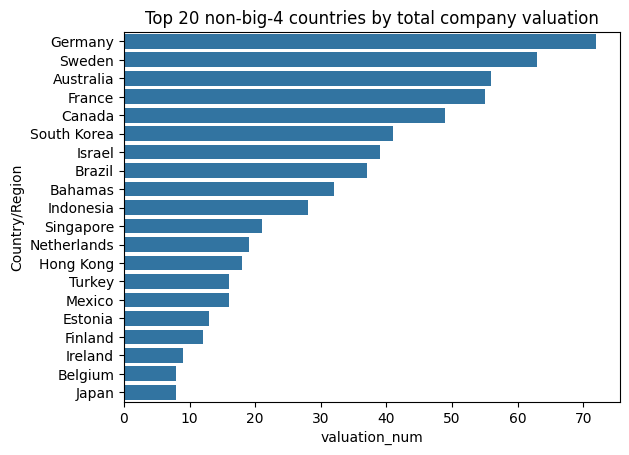

In [58]:
sns.barplot(data = big4.head(20),
            y = 'Country/Region',
            x = 'valuation_num')
plt.title("Top 20 non-big-4 countries by total company valuation")
plt.show()

In [59]:
data = big4

px.scatter_geo(data, 
               locations='Country/Region', 
               size='valuation_num', 
               locationmode='country names', 
               color='Country/Region',
               title='Total company valuations by country (non-big-four)')


/tmp/ipykernel_21174/267855705.py:3: DeprecationWarning: The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.
  px.scatter_geo(data,


ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'geo': 'geo',
              'hovertemplate': 'Country/Region=%{location}<br>valuation_num=%{marker.size}<extra></extra>',
              'legendgroup': 'Germany',
              'locationmode': 'country names',
              'locations': array(['Germany'], dtype=object),
              'marker': {'color': '#636efa',
                         'size': {'bdata': 'SA==', 'dtype': 'i1'},
                         'sizemode': 'area',
                         'sizeref': 0.18,
                         'symbol': 'circle'},
              'mode': 'markers',
              'name': 'Germany',
              'showlegend': True,
              'type': 'scattergeo'},
             {'geo': 'geo',
              'hovertemplate': 'Country/Region=%{location}<br>valuation_num=%{marker.size}<extra></extra>',
              'legendgroup': 'Sweden',
              'locationmode': 'country names',
              'locations': array(['Sweden'], dtype=object),
              'marker': {'color': '#EF553B',
                         'size': {'bdata': 'Pw==', 'dtype': 'i1'},
                         'sizemode': 'area',
                         'sizeref': 0.18,
                         'symbol': 'circle'},
              'mode': 'markers',
              'name': 'Sweden',
              'showlegend': True,
              'type': 'scattergeo'},
             {'geo': 'geo',
              'hovertemplate': 'Country/Region=%{location}<br>valuation_num=%{marker.size}<extra></extra>',
              'legendgroup': 'Australia',
              'locationmode': 'country names',
              'locations': array(['Australia'], dtype=object),
              'marker': {'color': '#00cc96',
                         'size': {'bdata': 'OA==', 'dtype': 'i1'},
                         'sizemode': 'area',
                         'sizeref': 0.18,
                         'symbol': 'circle'},
              'mode': 'markers',
              'name': 'Australia',
              'showlegend': True,
              'type': 'scattergeo'},
             {'geo': 'geo',
              'hovertemplate': 'Country/Region=%{location}<br>valuation_num=%{marker.size}<extra></extra>',
              'legendgroup': 'France',
              'locationmode': 'country names',
              'locations': array(['France'], dtype=object),
              'marker': {'color': '#ab63fa',
                         'size': {'bdata': 'Nw==', 'dtype': 'i1'},
                         'sizemode': 'area',
                         'sizeref': 0.18,
                         'symbol': 'circle'},
              'mode': 'markers',
              'name': 'France',
              'showlegend': True,
              'type': 'scattergeo'},
             {'geo': 'geo',
              'hovertemplate': 'Country/Region=%{location}<br>valuation_num=%{marker.size}<extra></extra>',
              'legendgroup': 'Canada',
              'locationmode': 'country names',
              'locations': array(['Canada'], dtype=object),
              'marker': {'color': '#FFA15A',
                         'size': {'bdata': 'MQ==', 'dtype': 'i1'},
                         'sizemode': 'area',
                         'sizeref': 0.18,
                         'symbol': 'circle'},
              'mode': 'markers',
              'name': 'Canada',
              'showlegend': True,
              'type': 'scattergeo'},
             {'geo': 'geo',
              'hovertemplate': 'Country/Region=%{location}<br>valuation_num=%{marker.size}<extra></extra>',
              'legendgroup': 'South Korea',
              'locationmode': 'country names',
              'locations': array(['South Korea'], dtype=object),
              'marker': {'color': '#19d3f3',
                         'size': {'bdata': 'KQ==', 'dtype': 'i1'},
                         'sizemode': 'area',
                         'sizeref': 0.18,
                         'symbol': 'circle'},
              'mode': 'markers',
              'name': 'South Korea',
              'showlegend': True,
              'type': '

- cleaning
    - You check for outliers, missing data, and needs for conversions or transformations. 

- Validating 
    - After cleaning, you double check the changes you made are correct and accurate. 



- Presenting 
    - You share your dataset with a peer